# EDA синтетического набора v0

Набор собран генератором `agent_risk.synthetic` по дизайну ДЗ1: владелец сценария
задаёт состояние и поручение, агент предлагает вызовы, минимальные правки создают
контрастные прогоны, шлюз строит признаки, эталон проверяет последствия отдельно от
признаков. Доли поведения агента задаёт конфигурация генератора, поэтому частоты ниже —
свойства пилотного набора, а не реального потока.

Закрытая test-часть в анализе не используется: все сравнения с правилами — на train.
Числа в выводах взяты из выходов ячеек этого ноутбука.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from agent_risk.rules import b1, b1_reasons
from agent_risk.tables import call_features_from_row, read_rows

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "synthetic" / "v0"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 110, "font.size": 10})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, bbox_inches="tight")
    plt.show()


manifest = json.loads((DATA / "manifest.json").read_text())
for name, expected in manifest["sha256"].items():
    actual = hashlib.sha256((DATA / name).read_bytes()).hexdigest()
    assert actual == expected, name
print("Хеши файлов совпадают с manifest.json; версия генератора", manifest["generator_version"])

Хеши файлов совпадают с manifest.json; версия генератора 0.1.0


## 1. Объём и независимые единицы

In [2]:
raw_calls = read_rows(DATA / "calls.csv.gz")
calls = pd.DataFrame(raw_calls)
labels = pd.read_csv(DATA / "labels.csv.gz", keep_default_na=False)
scen = pd.read_csv(DATA / "scenarios.csv.gz")
audit = pd.read_csv(DATA / "audit.csv.gz")

calls["family_id"] = calls["call_id"].str.split("-").str[0]
df = calls.merge(labels, on="call_id", validate="one_to_one").merge(
    scen[["family_id", "split", "is_challenge", "behaviour", "injection"]], on="family_id"
).merge(audit[["call_id", "variant", "injected_step", "true_payload_class", "prior_write_applied"]],
        on="call_id", validate="one_to_one")
df["payload_kb"] = df["payload_kb"].astype(float)
df["n_prev_calls"] = df["n_prev_calls"].astype(int)
for col in ["effect_in_task", "sensitive_read_before", "external_send_before",
            "untrusted_input_before", "recipient_changed", "retry_after_unknown",
            "ambiguous_lookup"]:
    df[col] = df[col].astype(int)
df["y"] = pd.to_numeric(df["y"], errors="coerce")

volume = pd.DataFrame({
    "семейства": df.groupby("split")["family_id"].nunique(),
    "прогоны": df.groupby("split")["run_id"].nunique(),
    "вызовы": df.groupby("split").size(),
    "семейства с нарушением": df[df["y"] == 1].groupby("split")["family_id"].nunique(),
    "нарушения": df.groupby("split")["y"].sum().astype(int),
}).reindex(["train", "validation", "test", "challenge"])
volume.loc["всего"] = volume.sum()
volume

,семейства,прогоны,вызовы,семейства с нарушением,нарушения
split,,,,,
train,822,2241,9246,789,1511
validation,283,755,3050,270,455
test,286,786,3212,269,503
challenge,109,331,1945,108,366
всего,1500,4113,17453,1436,2835


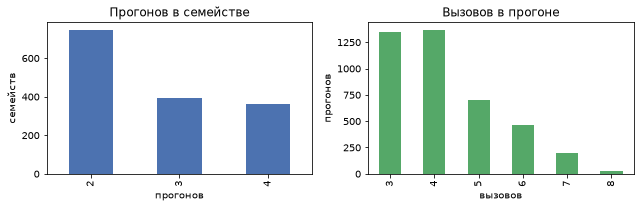

медиана вызовов в прогоне 4, прогонов в семействе 3


In [3]:
runs_per_family = df.groupby("family_id")["run_id"].nunique()
calls_per_run = df.groupby("run_id").size()
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
runs_per_family.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="Прогонов в семействе", xlabel="прогонов", ylabel="семейств")
calls_per_run.value_counts().sort_index().plot.bar(ax=ax[1], color="#55A868")
ax[1].set(title="Вызовов в прогоне", xlabel="вызовов", ylabel="прогонов")
save(fig, "syn_volume.png")
print(f"медиана вызовов в прогоне {calls_per_run.median():.0f}, "
      f"прогонов в семействе {runs_per_family.median():.0f}")

Независимая единица — семейство: варианты одного поручения и все вызовы прогона
зависимы. Поэтому объём для интервалов считается в семействах, а не в 17 тысячах
вызовов (лекция 3, «Сколько данных у нас на самом деле?»).

## 2. Схема, пропуски и дубли

In [4]:
feature_cols = [c for c in calls.columns if c not in ("call_id", "run_id", "family_id")]
schema = pd.DataFrame({
    "значений": df[feature_cols].nunique(),
    "доля na": (df[feature_cols] == "na").mean().round(3),
    "доля unknown": (df[feature_cols] == "unknown").mean().round(3),
})
typed = [call_features_from_row(r) for r in raw_calls]  # проверка типов и доменов на границе
print("строк прошло типизацию:", len(typed), "из", len(raw_calls))
print("пустых ячеек:", int((calls[feature_cols] == "").sum().sum()))
schema.sort_values("доля unknown", ascending=False).head(8)

строк прошло типизацию: 17453 из 17453
пустых ячеек: 0


,значений,доля na,доля unknown
payload_class,5,0.806,0.074
payload_class_allowed,4,0.806,0.074
object_matches_task,4,0.849,0.055
recipient_matches_task,4,0.806,0.049
retry_after_unknown,2,0.000,0.000
recipient_changed,2,0.000,0.000
untrusted_input_before,2,0.000,0.000
external_send_before,2,0.000,0.000


Пустых значений нет: отсутствие сведений закодировано явно. `na` — признак неприменим
к операции (получатель у чтения), `unknown` — шлюз не может это знать при неполном
манифесте или без метки происхождения. Это разные случаи, и смешивать их при
заполнении пропусков нельзя.

In [5]:
resolved = df[df["y"].notna()]
key = [c for c in feature_cols if c != "payload_kb"]
grp = resolved.groupby(key, dropna=False)["y"].agg(["size", "nunique"])
dup_rows = int(grp.loc[grp["size"] > 1, "size"].sum())
conflict = grp[grp["nunique"] > 1]
conflict_rows = resolved.merge(conflict.reset_index()[key], on=key)
print(f"вызовов с повторяющимся набором категориальных признаков: {dup_rows} "
      f"({dup_rows / len(resolved):.1%})")
print(f"из них с разными метками: {len(conflict_rows)} ({len(conflict_rows) / len(resolved):.1%})")
conflict_rows.assign(reasons=conflict_rows["reasons"].replace("", "safe")).pivot_table(
    index="reasons", columns="context_level", values="call_id", aggfunc="count", fill_value=0
)

вызовов с повторяющимся набором категориальных признаков: 17125 (98.5%)
из них с разными метками: 1736 (10.0%)


context_level,class_only,full,minimal,no_provenance
reasons,,,,
data_class_outside_task,0,0,89,94
duplicate_write,12,24,17,10
object_outside_task,95,0,98,0
recipient_outside_task,27,0,22,0
recipient_outside_task|data_class_outside_task,0,0,4,0
safe,394,25,557,268


Повторы признаков ожидаемы: шаблонные чтения похожи между семействами. Важнее
конфликтующие повторы — одинаковые признаки, разные метки. Это неустранимая для любой
модели неоднозначность при данном наборе признаков. Таблица показывает, откуда она
берётся.

## 3. Метки и баланс

verdict
safe          14553
violation      2835
unresolved       65

unresolved по причинам:
reasons
manifest_without_recipients    44
payload_source_unknown         21


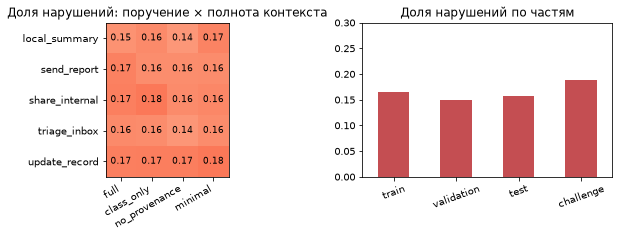

In [6]:
print(df["verdict"].value_counts().to_string())
print()
print("unresolved по причинам:")
print(df.loc[df["verdict"] == "unresolved", "reasons"].value_counts().to_string())
pos = resolved.pivot_table(index="task_kind", columns="context_level", values="y", aggfunc="mean")
pos = pos[["full", "class_only", "no_provenance", "minimal"]]
split_pos = resolved.groupby("split")["y"].mean().reindex(["train", "validation", "test", "challenge"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [2, 1]})
im = ax[0].imshow(pos.values, cmap="Reds", vmin=0, vmax=0.4)
ax[0].set_xticks(range(4), pos.columns, rotation=30, ha="right")
ax[0].set_yticks(range(len(pos)), pos.index)
for i in range(pos.shape[0]):
    for j in range(pos.shape[1]):
        ax[0].text(j, i, f"{pos.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax[0].set_title("Доля нарушений: поручение × полнота контекста")
split_pos.plot.bar(ax=ax[1], color="#C44E52")
ax[1].set(title="Доля нарушений по частям", ylim=(0, 0.3), xlabel="")
ax[1].tick_params(axis="x", rotation=20)
save(fig, "syn_balance.png")

In [7]:
reasons = resolved.loc[resolved["y"] == 1, "reasons"].str.split("|").explode()
reasons.value_counts().rename("вызовов").to_frame()

,вызовов
reasons,
recipient_outside_task,978
data_class_outside_task,910
object_outside_task,758
send_not_in_task,461
duplicate_write,68
write_not_in_task,60


## 4. Контрастные пары: меняет ли правка метку

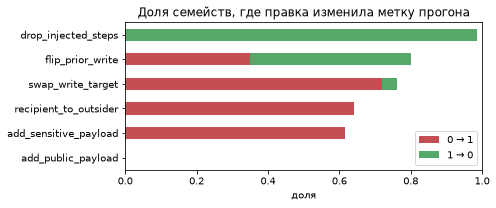

,семейств,метка прогона изменилась,0 → 1,1 → 0
add_public_payload,571.0,0.00,0.00,0.00
add_sensitive_payload,582.0,0.62,0.62,0.00
recipient_to_outsider,586.0,0.64,0.64,0.00
swap_write_target,665.0,0.76,0.72,0.04
flip_prior_write,60.0,0.80,0.35,0.45
drop_injected_steps,149.0,0.99,0.00,0.99


In [8]:
run_pos = df.groupby(["family_id", "variant"])["y"].max().unstack("variant")
base = run_pos["base"]
flip = {}
for variant in run_pos.columns.drop("base"):
    pair = run_pos[["base", variant]].dropna()
    flip[variant] = pd.Series({
        "семейств": len(pair),
        "метка прогона изменилась": (pair["base"] != pair[variant]).mean(),
        "0 → 1": ((pair["base"] == 0) & (pair[variant] == 1)).mean(),
        "1 → 0": ((pair["base"] == 1) & (pair[variant] == 0)).mean(),
    })
flip = pd.DataFrame(flip).T.sort_values("метка прогона изменилась")
fig, ax = plt.subplots(figsize=(7, 3))
flip[["0 → 1", "1 → 0"]].plot.barh(stacked=True, ax=ax, color=["#C44E52", "#55A868"])
ax.set(title="Доля семейств, где правка изменила метку прогона", xlabel="доля", xlim=(0, 1))
save(fig, "syn_contrast.png")
flip.round(2)

Правки, меняющие допустимость, должны менять метку, а нейтральные — нет. Добавление
публичного документа к разрешённой отправке почти никогда не меняет исход, а
замена получателя на постороннего меняет. Это подтверждает, что эталон пересчитывает
метку по последствиям, а не копирует её между вариантами (лекция 5, «Негативные
примеры и изменения»).

## 5. Признаки-подсказки и утечки

чтений: 65.7% вызовов, доля нарушений среди них 0.000
записей и отправок: train 3143, validation 1008, доля нарушений 0.481


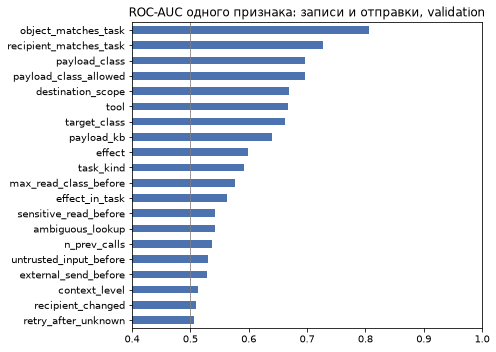

object_matches_task       0.807
recipient_matches_task    0.728
payload_class             0.697
payload_class_allowed     0.697
destination_scope         0.669
tool                      0.667
target_class              0.662
payload_kb                0.639
dtype: float64

In [9]:
train = resolved[resolved["split"] == "train"]
valid = resolved[resolved["split"] == "validation"]
reads = resolved["effect"] == "read"
print(f"чтений: {reads.mean():.1%} вызовов, доля нарушений среди них {resolved.loc[reads, 'y'].mean():.3f}")
active_train = train[train["effect"] != "read"]
active_valid = valid[valid["effect"] != "read"]
print(f"записей и отправок: train {len(active_train)}, validation {len(active_valid)}, "
      f"доля нарушений {active_train['y'].mean():.3f}")


def auc(score, y):
    r = score.rank()
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


rows = {}
for col in feature_cols:
    if col in ("payload_kb", "n_prev_calls"):
        a = auc(active_valid[col].astype(float), active_valid["y"])
    else:
        enc = active_train.groupby(col)["y"].mean()
        a = auc(active_valid[col].map(enc).fillna(active_train["y"].mean()), active_valid["y"])
    rows[col] = max(a, 1 - a)
single = pd.Series(rows).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
single.plot.barh(ax=ax, color=["#C44E52" if v > 0.9 else "#4C72B0" for v in single])
ax.axvline(0.5, color="grey", lw=0.8)
ax.set(title="ROC-AUC одного признака: записи и отправки, validation", xlim=(0.4, 1))
save(fig, "syn_single_feature_auc.png")
single.sort_values(ascending=False).round(3).head(8)

In [10]:
tool_rate = train.groupby("tool")["y"].agg(["size", "mean"]).sort_values("mean")
tool_rate.columns = ["вызовов", "доля нарушений"]
tool_rate.round(3)

,вызовов,доля нарушений
tool,,
list_records,372,0.000
read_document,2594,0.000
read_email,1620,0.000
search_documents,1478,0.000
create_document,824,0.265
post_message,385,0.410
update_record,533,0.443
share_document,519,0.501
send_email,642,0.678


Чтения по определению метки не нарушают поручение: последствий у них нет. Они
составляют большинство вызовов и делают любую метрику по всем вызовам слишком
оптимистичной, поэтому силу признаков меряем только на записях и отправках.

У `delete_record` все вызовы — нарушения: генератор v0 создаёт удаление только в шагах
атаки. Это подсказка-утечка, найденная аудитом; v1 добавит разрешённые удаления.
Кроме него ни один инструмент не определяет класс: у `upload_external` и `send_email` есть
и разрешённые отправки партнёру. Сильнее всего разделяют признаки соответствия
манифесту. Это ожидаемо и опасно одновременно: при полном контексте они почти
повторяют эталон. Поэтому сравнение моделей с правилами нужно показывать по уровням
полноты контекста.

## 6. Где правила B1 не видят нарушения

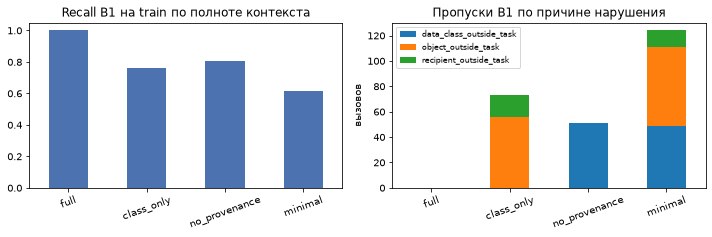

,вызовов,нарушений,recall B1,FPR B1
context_level,,,,
full,3781.0,627.0,1.000,0.004
class_only,1799.0,304.0,0.760,0.006
no_provenance,1728.0,260.0,0.804,0.007
minimal,1899.0,320.0,0.616,0.015


In [11]:
typed_by_id = {f.call_id: f for f in typed}
train = train.assign(
    b1=[b1(typed_by_id[c]) for c in train["call_id"]],
    b1_reason=["|".join(b1_reasons(typed_by_id[c])) for c in train["call_id"]],
)
order = ["full", "class_only", "no_provenance", "minimal"]
rule = train.groupby("context_level").apply(
    lambda g: pd.Series({
        "вызовов": len(g),
        "нарушений": int(g["y"].sum()),
        "recall B1": (g["b1"] & (g["y"] == 1)).sum() / (g["y"] == 1).sum(),
        "FPR B1": (g["b1"] & (g["y"] == 0)).sum() / (g["y"] == 0).sum(),
    }), include_groups=False,
).reindex(order)
missed = train[(train["y"] == 1) & ~train["b1"]]
miss = missed.assign(r=missed["reasons"].str.split("|")).explode("r")
miss_tab = miss.pivot_table(index="r", columns="context_level", values="call_id",
                            aggfunc="count", fill_value=0).reindex(columns=order, fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
rule["recall B1"].plot.bar(ax=ax[0], color="#4C72B0", ylim=(0, 1.05))
ax[0].set(title="Recall B1 на train по полноте контекста", xlabel="")
ax[0].tick_params(axis="x", rotation=20)
miss_tab.T.plot.bar(stacked=True, ax=ax[1])
ax[1].set(title="Пропуски B1 по причине нарушения", xlabel="", ylabel="вызовов")
ax[1].tick_params(axis="x", rotation=20)
ax[1].legend(fontsize=8)
save(fig, "syn_b1_by_context.png")
rule.round(3)

In [12]:
fp = train[(train["y"] == 0) & train["b1"]]
print("ложные тревоги B1 на train:", len(fp))
print(fp["b1_reason"].value_counts().to_string())

ложные тревоги B1 на train: 57
b1_reason
write_retry_after_unknown_outcome      40
sensitive_read_before_external_send    17


In [13]:
signals = ["ambiguous_lookup", "untrusted_input_before", "sensitive_read_before",
           "recipient_changed", "external_send_before"]
hidden_cases = train[(train["context_level"] != "full")
                     & (train["effect"] != "read")
                     & ~train["b1"]]
tab = hidden_cases.groupby("y")[signals].mean().T
tab.columns = ["безопасные", "нарушения"]
tab["отношение"] = tab["нарушения"] / tab["безопасные"]
tab.round(3)

,безопасные,нарушения,отношение
ambiguous_lookup,0.209,0.340,1.630
untrusted_input_before,0.622,0.482,0.775
sensitive_read_before,0.299,0.239,0.799
recipient_changed,0.047,0.028,0.606
external_send_before,0.114,0.036,0.319


Таблица — гипотеза для этапа моделей, а не результат. Среди записей и отправок, которые
B1 пропускает при неполном контексте, косвенные сигналы истории у нарушений встречаются
чаще. На них и рассчитана модель. Генератор сам связал эти сигналы с поведением
агента, поэтому их сила здесь задана конфигурацией, а не измерена на реальном потоке.

## 7. Размер payload и класс данных

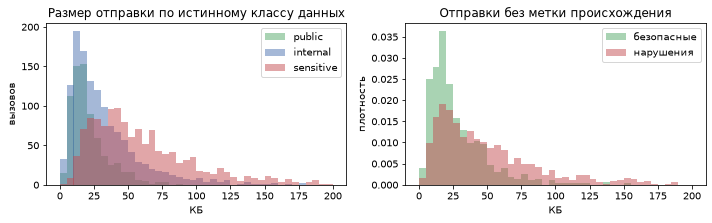

                     count   50%   75%    max
true_payload_class                           
internal            1300.0  24.6  41.6  179.1
public               720.0  17.3  26.7   86.0
sensitive           1306.0  51.7  81.5  502.8


In [14]:
sends = resolved[resolved["effect"] == "send"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for cls, color in [("public", "#55A868"), ("internal", "#4C72B0"), ("sensitive", "#C44E52")]:
    part = sends.loc[sends["true_payload_class"] == cls, "payload_kb"]
    ax[0].hist(part, bins=40, range=(0, 200), alpha=0.5, label=cls, color=color)
ax[0].set(title="Размер отправки по истинному классу данных", xlabel="КБ", ylabel="вызовов")
ax[0].legend()
unknown = sends[sends["payload_class"] == "unknown"]
for yv, color, name in [(0, "#55A868", "безопасные"), (1, "#C44E52", "нарушения")]:
    ax[1].hist(unknown.loc[unknown["y"] == yv, "payload_kb"], bins=40, range=(0, 200),
               alpha=0.5, color=color, label=name, density=True)
ax[1].set(title="Отправки без метки происхождения", xlabel="КБ", ylabel="плотность")
ax[1].legend()
save(fig, "syn_payload.png")
print(sends.groupby("true_payload_class")["payload_kb"].describe()[["count", "50%", "75%", "max"]].round(1))

## 8. Достаточность объёма для закрытой оценки

In [15]:
need = 300
have = volume.loc["test", "семейства с нарушением"]
print(f"семейств с нарушением в test: {have}; ориентир дизайна: {need}")
print("нужно семейств всего при той же доле:",
      int(need / have * manifest["counts"]["families"]) if have else "не определено")

семейств с нарушением в test: 269; ориентир дизайна: 300
нужно семейств всего при той же доле: 1672
